Employee Satisfaction Dataset:
   Salary_Satisfaction  Benefits_Satisfaction  Pay_Fairness  Team_Spirit  \
0                  4.0                    4.0           4.0          3.0   
1                  3.0                    3.0           3.0          2.0   
2                  4.0                    4.0           3.0          3.0   
3                  5.0                    5.0           5.0          3.0   
4                  3.0                    3.0           3.0          2.0   

   Manager_Support  Work_Environment  Workload_Balance  Career_Growth  \
0              2.0               2.0               2.0            3.0   
1              2.0               3.0               3.0            2.0   
2              3.0               3.0               5.0            4.0   
3              4.0               3.0               4.0            5.0   
4              2.0               4.0               3.0            4.0   

   Training_Opportunities  Promotion_Opportunities  
0                   

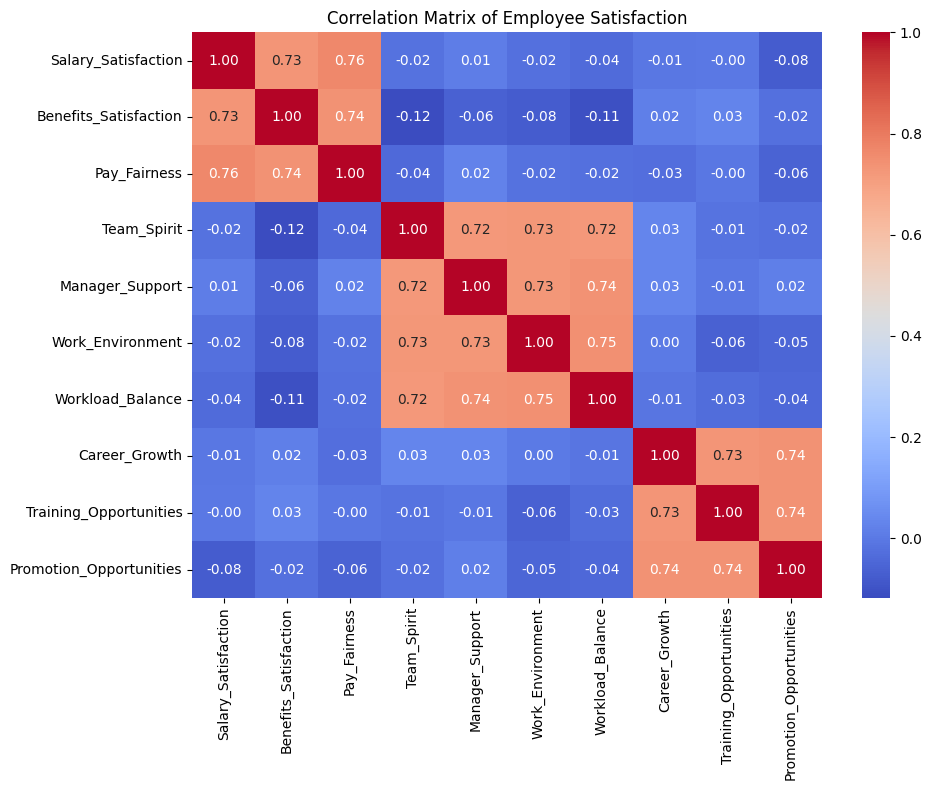


Factor Analysis with 2 Factors
Log Likelihood: -11.899869985515506

Factor Analysis with 3 Factors
Log Likelihood: -10.97055532629609

Factor Analysis with 4 Factors
Log Likelihood: -10.961109677045533

Factor Loadings:
                         Factor 1  Factor 2  Factor 3
Salary_Satisfaction        -0.198    -0.765     0.362
Benefits_Satisfaction      -0.278    -0.708     0.376
Pay_Fairness               -0.197    -0.774     0.366
Team_Spirit                 0.828    -0.112     0.115
Manager_Support             0.827    -0.155     0.161
Work_Environment            0.840    -0.152     0.093
Workload_Balance            0.848    -0.134     0.093
Career_Growth              -0.025     0.390     0.761
Training_Opportunities     -0.075     0.387     0.763
Promotion_Opportunities    -0.057     0.450     0.739

Varimax Rotated Loadings:
                         Factor 1  Factor 2  Factor 3
Salary_Satisfaction         0.002    -0.869    -0.024
Benefits_Satisfaction      -0.084    -0.844     0.

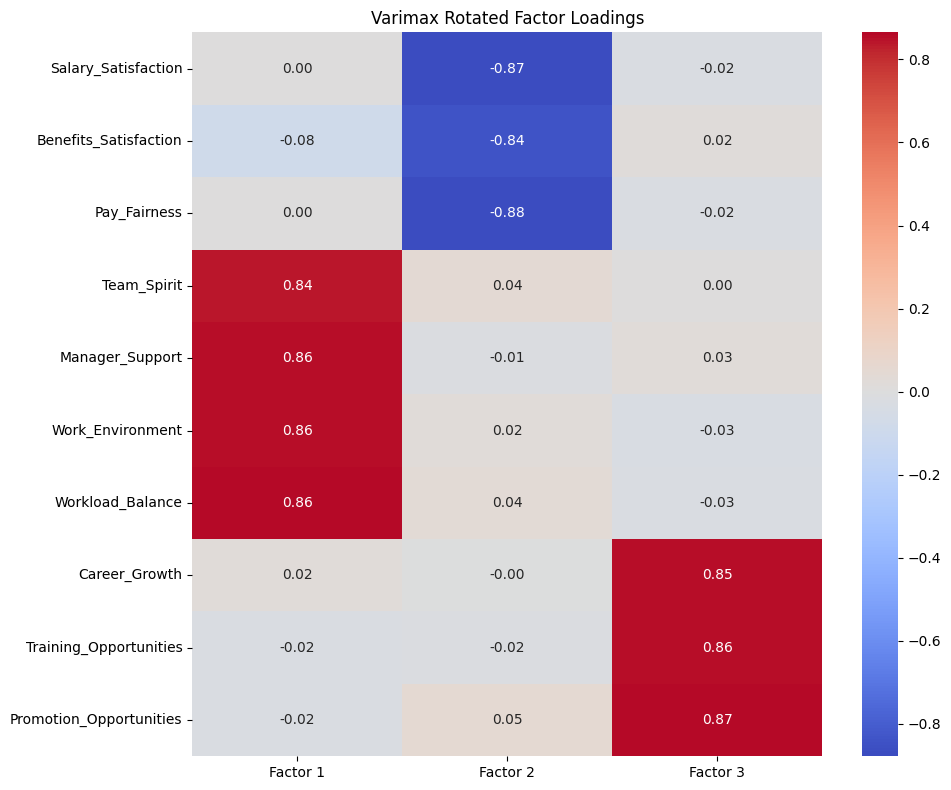


Factor Interpretation:

Factor 1:
Workload_Balance : 0.863
Work_Environment : 0.858
Manager_Support : 0.856

Factor 2:
Pay_Fairness : -0.878
Salary_Satisfaction : -0.869
Benefits_Satisfaction : -0.844

Factor 3:
Promotion_Opportunities : 0.865
Training_Opportunities : 0.858
Career_Growth : 0.855

PCA Explained Variance Ratio:
[0.323 0.253 0.241]

PCA Total Variance Explained:
0.818

Factor Analysis Noise Variance:
[0.244 0.28  0.229 0.288 0.266 0.262 0.254 0.269 0.263 0.248]


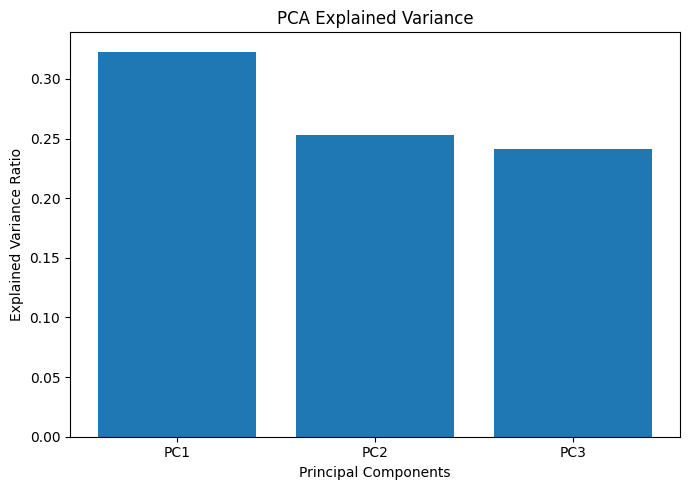


PCA vs Factor Analysis:
            Method  Components  Variance / Model Information
0              PCA           3                         0.818
1  Factor Analysis           3                       -10.971


In [24]:

# EXPERIMENT 21: FACTOR ANALYSIS AND LATENT FACTOR INTERPRETATION

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import FactorAnalysis, PCA

# --------------------------------------------------
# 1. GENERATE EMPLOYEE SATISFACTION SURVEY DATA
# --------------------------------------------------

np.random.seed(42)

n_employees = 300

# Generate three hidden factors
compensation = np.random.normal(0, 1, n_employees)
work_culture = np.random.normal(0, 1, n_employees)
career_growth = np.random.normal(0, 1, n_employees)

# Generate 10 survey questions (Likert scale 1-5)
data = {
    'Salary_Satisfaction': 3 + compensation + np.random.normal(0, 0.5, n_employees),
    'Benefits_Satisfaction': 3 + compensation + np.random.normal(0, 0.5, n_employees),
    'Pay_Fairness': 3 + compensation + np.random.normal(0, 0.5, n_employees),

    'Team_Spirit': 3 + work_culture + np.random.normal(0, 0.5, n_employees),
    'Manager_Support': 3 + work_culture + np.random.normal(0, 0.5, n_employees),
    'Work_Environment': 3 + work_culture + np.random.normal(0, 0.5, n_employees),
    'Workload_Balance': 3 + work_culture + np.random.normal(0, 0.5, n_employees),

    'Career_Growth': 3 + career_growth + np.random.normal(0, 0.5, n_employees),
    'Training_Opportunities': 3 + career_growth + np.random.normal(0, 0.5, n_employees),
    'Promotion_Opportunities': 3 + career_growth + np.random.normal(0, 0.5, n_employees)
}

df = pd.DataFrame(data)

# Convert responses to Likert scale (1-5)
df = df.round().clip(1, 5)

print("Employee Satisfaction Dataset:")
print(df.head())

print("\nDataset Shape:", df.shape)

# --------------------------------------------------
# 2. CHECK CORRELATION
# --------------------------------------------------

plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title("Correlation Matrix of Employee Satisfaction")
plt.tight_layout()
plt.show()

# --------------------------------------------------
# 3. STANDARDIZE DATA
# --------------------------------------------------

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)

# --------------------------------------------------
# 4. FIT FACTOR ANALYSIS WITH 2, 3 AND 4 FACTORS
# --------------------------------------------------

for n_factors in [2, 3, 4]:

    fa = FactorAnalysis(n_components=n_factors, random_state=42)
    fa.fit(X_scaled)

    print(f"\nFactor Analysis with {n_factors} Factors")
    print("Log Likelihood:", fa.score(X_scaled))

# --------------------------------------------------
# 5. FIT THREE-FACTOR MODEL
# --------------------------------------------------

fa = FactorAnalysis(n_components=3, random_state=42)
fa.fit(X_scaled)

loadings = fa.components_.T

loadings_df = pd.DataFrame(
    loadings,
    index=df.columns,
    columns=['Factor 1', 'Factor 2', 'Factor 3']
)

print("\nFactor Loadings:")
print(loadings_df.round(3))

# --------------------------------------------------
# 6. VARIMAX ROTATION
# --------------------------------------------------

def varimax(Phi, gamma=1.0, q=20, tol=1e-6):

    p, k = Phi.shape
    R = np.eye(k)
    d = 0

    for i in range(q):

        d_old = d
        Lambda = Phi @ R

        u, s, vh = np.linalg.svd(
            Phi.T @ (
                Lambda**3 -
                (gamma / p) * Lambda @ np.diag(
                    np.diag(Lambda.T @ Lambda)
                )
            )
        )

        R = u @ vh
        d = np.sum(s)

        if d_old != 0 and d / d_old < 1 + tol:
            break

    return Phi @ R

rotated_loadings = varimax(loadings)

rotated_df = pd.DataFrame(
    rotated_loadings,
    index=df.columns,
    columns=['Factor 1', 'Factor 2', 'Factor 3']
)

print("\nVarimax Rotated Loadings:")
print(rotated_df.round(3))

# --------------------------------------------------
# 7. VISUALIZE ROTATED LOADINGS
# --------------------------------------------------

plt.figure(figsize=(10, 8))

sns.heatmap(
    rotated_df,
    annot=True,
    cmap='coolwarm',
    center=0,
    fmt='.2f'
)

plt.title("Varimax Rotated Factor Loadings")
plt.tight_layout()
plt.show()

# --------------------------------------------------
# 8. INTERPRET FACTORS
# --------------------------------------------------

print("\nFactor Interpretation:")

for factor in rotated_df.columns:

    print(f"\n{factor}:")

    top_questions = rotated_df[factor].abs().sort_values(
        ascending=False
    ).head(3)

    for question in top_questions.index:
        print(question, ":", round(rotated_df.loc[question, factor], 3))

# --------------------------------------------------
# 9. COMPARE FACTOR ANALYSIS WITH PCA
# --------------------------------------------------

pca = PCA(n_components=3)
pca.fit(X_scaled)

print("\nPCA Explained Variance Ratio:")
print(np.round(pca.explained_variance_ratio_, 3))

print("\nPCA Total Variance Explained:")
print(round(np.sum(pca.explained_variance_ratio_), 3))

print("\nFactor Analysis Noise Variance:")
print(np.round(fa.noise_variance_, 3))

# --------------------------------------------------
# 10. VISUALIZE PCA EXPLAINED VARIANCE
# --------------------------------------------------

plt.figure(figsize=(7, 5))

plt.bar(
    ['PC1', 'PC2', 'PC3'],
    pca.explained_variance_ratio_
)

plt.title("PCA Explained Variance")
plt.xlabel("Principal Components")
plt.ylabel("Explained Variance Ratio")

plt.tight_layout()
plt.show()

# --------------------------------------------------
# 11. COMPARE PCA AND FACTOR ANALYSIS
# --------------------------------------------------

comparison = pd.DataFrame({
    'Method': ['PCA', 'Factor Analysis'],
    'Components': [3, 3],
    'Variance / Model Information': [
        round(np.sum(pca.explained_variance_ratio_), 3),
        round(fa.score(X_scaled), 3)
    ]
})

print("\nPCA vs Factor Analysis:")
print(comparison)
